In [12]:
import pandas as pd

df = pd.read_csv("../data/ecommerce_sales.csv")

print(df.head())

   order_id        date       city     category   price  units  revenue
0    100000  2024-04-19  Stockholm       Sports  530.95      4  2123.80
1    100001  2024-05-06      Malmö       Sports  653.28      3  1959.84
2    100002  2024-03-07    Uppsala     Clothing  177.98      4   711.92
3    100003  2024-04-08   Göteborg         Home  348.57      3  1045.71
4    100004  2024-01-18    Uppsala  Electronics  777.07      3  2331.21


In [13]:
import sys
sys.path.append("../src")

from io_utils import load_data

df = load_data("../data/ecommerce_sales.csv")
print("To display the first five rows")
print(df.head()) 
print("Shape means to display the data size:", df.shape) # says data sizes
print("Columns:", df.columns) 

print(df.info()) # to check the datatypes




To display the first five rows
   order_id        date       city     category   price  units  revenue
0    100000  2024-04-19  Stockholm       Sports  530.95      4  2123.80
1    100001  2024-05-06      Malmö       Sports  653.28      3  1959.84
2    100002  2024-03-07    Uppsala     Clothing  177.98      4   711.92
3    100003  2024-04-08   Göteborg         Home  348.57      3  1045.71
4    100004  2024-01-18    Uppsala  Electronics  777.07      3  2331.21
Shape means to display the data size: (2500, 7)
Columns: Index(['order_id', 'date', 'city', 'category', 'price', 'units', 'revenue'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2

In [14]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].dtype)
print(df["date"].head())

datetime64[us]
0   2024-04-19
1   2024-05-06
2   2024-03-07
3   2024-04-08
4   2024-01-18
Name: date, dtype: datetime64[us]


In [15]:
print("Missing values:")
print(df.isnull().sum()) 


Missing values:
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64


In [16]:
print("Duplicate rows:", df.duplicated().sum()) 

Duplicate rows: 0


In [17]:
print("First date:", df["date"].min())
print("\nLast date:", df["date"].max())

First date: 2024-01-01 00:00:00

Last date: 2024-06-30 00:00:00


In [18]:
print("Total rows:", len(df)) 
print("Unique orders:", df["order_id"].nunique())


Total rows: 2500
Unique orders: 2500


In [19]:
import importlib
import metrics

from metrics import top_3_categories

print("\nTop 3 categories by revenue:")
print(top_3_categories(df))



Top 3 categories by revenue:
category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64


In [ ]:
import pandas as pd
df = pd.read_csv("../data/ecommerce_sales.csv")
df.head()

# Kontroll av datan
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

import sys
sys.path.append("../src")

from metrics import total_revenue
print("Totala intäkter: ", round(total_revenue(df),2))

from metrics import total_units
print("Totalt antal enheter: ", total_units(df))

order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Duplicate rows: 0
Totala intäkter:  3502767.23
Totalt antal enheter:  7463


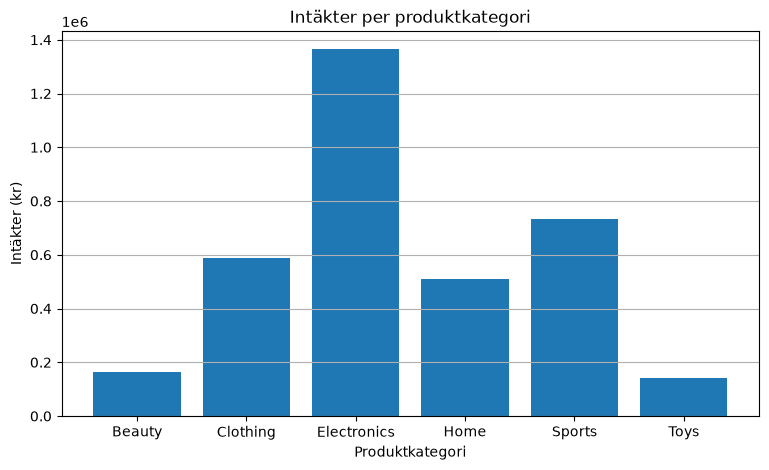

In [ ]:
import sys
import matplotlib.pyplot as plt
sys.path.append("..")
from src import viz as V

revenue = df.groupby("category")["revenue"].sum()
fig, ax = plt.subplots(figsize=(9, 5))
V.bar(ax, revenue.index, revenue.values,
    "Intäkter per produktkategori",
    "Produktkategori",
    "Intäkter (kr)"
)
plt.show()

# Diagrammet visar de totala intäkterna för varje produktkategori. 
# Electronics har de högsta intäkterna jämfört med de andra kategorierna.

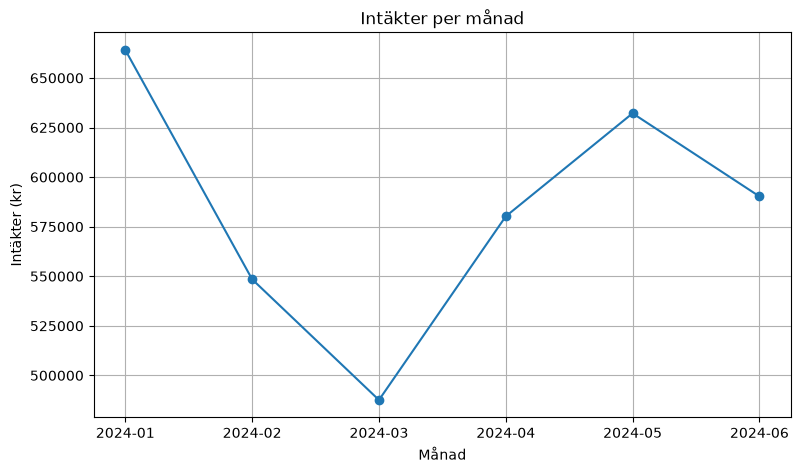

In [ ]:
import sys
import matplotlib.pyplot as plt
sys.path.append("../src")
import metrics
import viz as V

monthly_revenue = metrics.revenue_by_month(df)
fig, ax = plt.subplots(figsize=(9, 5))
V.line(ax, monthly_revenue.index.astype(str), monthly_revenue.values,
    "Intäkter per månad",
    "Månad",
    "Intäkter (kr)"
)
plt.show()

# Diagrammet visar intäkterna per månad.
# Januari hade högst intäkter och mars lägst intäkter.